### Baseline DeepONet: two splitting protocols, **Pipeline.** CO2 GCS dataset -> preprocessing -> physics-based feature engineering ->case-level splitting -> feature scaling -> Baseline DeepONet -> metrics -> decision support.**Architecture.** Four independent sigmoid heads. Closure (STTI+RTI+STI+MTI = 1) is encouraged by a penalty only, so predictions can leave the simplex.All modelling code lives in the `co2gcs` package so that the four notebooks shareone implementation. Put `co2gcs/` and `All_dataset.csv` next to this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import co2gcs as CC
CC.plots.use_style()
SEED = 42
TARGETS = CC.TARGETS

## 1. Data and physics-based feature engineering

In [2]:
# ---- Load + physics-based feature engineering -------------------------------

# fix_injection=True restores each case's injection rate over the full trajectory.
# In the raw file, the column is zeroed for every t > 30 yr, which leaks the
# post-injection regime label and deletes the strongest control on long-term
# trapping across 85% of the horizon.

df = CC.load('All_dataset.csv', fix_injection=True)

Xb, Xt, y, names_b, names_t = CC.build_features(df, mode='orig')

groups = df['case'].values
tvals = df['Time (years)'].values

print(
    f'{len(df)} rows, {df.case.nunique()} simulation cases, '
    f'branch dim {Xb.shape[1]}, trunk dim {Xt.shape[1]}'
)

df.head()

47425 rows, 761 simulation cases, branch dim 10, trunk dim 1


,Index,Dykstra Parson Coefficient,Average Porosity,Injection rate (m3/day),Biots Coefficient,Young's Modulus (MPa),Poisson's Ratio,Perforation Thickness (m),Reservoir Thickness (m),Acquifer Salinity (PPM),Reservoir Temperature (oC),Time (years),STTI,RTI,STI,MTI,case,q_inj
0,1,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.41,0.1161,0.0014,0.8845,0.0019,0,2.4
1,2,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.50,0.2356,0.0011,0.7651,0.0019,0,2.4
2,3,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.58,0.3145,0.0010,0.6863,0.0019,0,2.4
3,4,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.67,0.3842,0.0009,0.6167,0.0018,0,2.4
4,5,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.75,0.4221,0.0010,0.5787,0.0019,0,2.4


## 2. Splitting protocols

In [3]:
# ---- The two splitting protocols --------------------------------------------

PROTOCOLS = ['random', 'group']


def get_split(protocol, fold=0):
    tr, va, te = CC.make_split(
        protocol,
        len(y),
        groups,
        seed=SEED,
        n_folds=5,
        fold=fold
    )

    # Scalers fit on TRAIN ONLY
    sb = StandardScaler().fit(Xb[tr])
    st = StandardScaler().fit(Xt[tr])

    pack = lambda m: (
        sb.transform(Xb[m]).astype('float32'),
        st.transform(Xt[m]).astype('float32'),
        y[m]
    )

    d = {}

    for nm, m in [('tr', tr), ('va', va), ('te', te)]:
        d[f'Xb_{nm}'], d[f'Xt_{nm}'], d[f'y_{nm}'] = pack(m)

    d.update(
        t_te=tvals[te],
        g_te=groups[te],
        mask_te=te,
        dims=(Xb.shape[1], Xt.shape[1]),
        scalers=(sb, st)
    )

    return d


for p in PROTOCOLS:
    d = get_split(p)

    print(
        f"{p:7s} "
        f"train {len(d['y_tr']):6d}  "
        f"val {len(d['y_va']):5d}  "
        f"test {len(d['y_te']):5d}  "
        f"test cases {len(np.unique(d['g_te'])):4d}"
    )

random  train  33199  val  7113  test  7113  test cases  761
group   train  30762  val  7057  test  9606  test cases  153


### Pros and cons of each protocol

In [4]:
for p in PROTOCOLS:
    n = CC.PROTOCOL_NOTES[p]

    print('=' * 78)
    print(n['name'])
    print('=' * 78)

    print(' PROS')
    [print('   +', x) for x in n['pros']]

    print(' CONS')
    [print('   -', x) for x in n['cons']]

    print()

Protocol 1 - random row split
 PROS
   + Maximises training rows for a fixed ensemble size.
   + Appropriate if the deployment task is gap-filling or temporal interpolation within simulations that are already available.
   + Low variance between repeats, so results look stable.
 CONS
   - Neighbouring timesteps of the same trajectory land in both train and test, so the test set is not independent of training.
   - Reported R2 measures interpolation along a seen curve, not generalisation to a new reservoir.
   - Smooth, slowly varying indices (MTI in particular) are inflated most, because the neighbouring years almost determine the answer.
   - Hides loss-weighting and feature defects that only appear when the model must extrapolate to an unseen case.

Protocol 2 - GroupKFold by simulation case
 PROS
   + Test cases are fully unseen, matching the site-screening use case where a new reservoir realisation must be scored.
   + Exposes genuine parameter-to-response learning rather than curv

## 3. Train and compare the protocols

In [5]:
# ---- Train one model per protocol -------------------------------------------

db, dt = Xb.shape[1], Xt.shape[1]

TRAIN_KW = dict(
    epochs=500,
    patience=20,
    bs=32,
    lr=1.5e-3,
    wd=8.5e-5,
    var_weight=True,
    closure_pen=1.0
)

results, preds, splits, models = [], {}, {}, {}

for p in PROTOCOLS:
    d = get_split(p)
    splits[p] = d

    CC.seed_all(SEED)

    drop, head, bayes = 0.0, 'point', False

    model = CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    model, hist = CC.train_model(
        model,
        d['Xb_tr'],
        d['Xt_tr'],
        d['y_tr'],
        d['Xb_va'],
        d['Xt_va'],
        d['y_va'],
        head= head,
        **TRAIN_KW
    )
    
    models[p] = model
    
    P = CC.predict_mean(
        model,
        d['Xb_te'],
        d['Xt_te']
    )

    preds[p] = P

    m = CC.accuracy(d['y_te'], P)
    m['protocol'] = p
    results.append(m)

    print(
        f"{p:7s} R2_mean={m['R2_mean']:.4f}  "
        + '  '.join(
            f'{t}={m[f"R2_{t}"]:.3f}'
            for t in TARGETS
        )
        + f"  closureMAE={m['closure_MAE']:.4f}"
    )

res = pd.DataFrame(results)[
    ['protocol']
    + [f'R2_{t}' for t in TARGETS]
    + ['R2_mean']
    + [f'RMSE_{t}' for t in TARGETS]
    + ['MAE_mean', 'closure_MAE']
]

res.round(4)

random  R2_mean=0.9831  STTI=0.980  RTI=0.992  STI=0.968  MTI=0.992  closureMAE=0.0005
group   R2_mean=0.8836  STTI=0.849  RTI=0.935  STI=0.810  MTI=0.941  closureMAE=0.0019


,protocol,R2_STTI,R2_RTI,R2_STI,R2_MTI,R2_mean,RMSE_STTI,RMSE_RTI,RMSE_STI,RMSE_MTI,MAE_mean,closure_MAE
0,random,0.9801,0.9918,0.9681,0.9922,0.9831,0.0283,0.0124,0.0255,0.0009,0.0098,0.0005
1,group,0.8494,0.9347,0.8096,0.9409,0.8836,0.0770,0.0354,0.0600,0.0021,0.0281,0.0019


### RandomKFold spread

In [6]:
# ---- 5-fold RandomKFold: fold-to-fold spread -------------------------------

fold_rows = []

for f in range(5):
    d = get_split('random', fold=f)

    CC.seed_all(SEED + f)

    drop, head, bayes = 0.0, 'point', False

    model = CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    model, _ = CC.train_model(
        model,
        d['Xb_tr'],
        d['Xt_tr'],
        d['y_tr'],
        d['Xb_va'],
        d['Xt_va'],
        d['y_va'],
        head='point',
        **TRAIN_KW
    )

    P = CC.predict_mean(
        model,
        d['Xb_te'],
        d['Xt_te']
    )

    # Calculate all metrics
    m = CC.accuracy(d['y_te'], P)
    m['fold'] = f
    fold_rows.append(m)

    # Print fold results
    print(f"\n{'=' * 65}")
    print(f"Fold {f}")
    print(f"{'=' * 65}")

    print(
        f"{'Index':<10}"
        f"{'R²':>12}"
        f"{'RMSE':>12}"
        f"{'MAE':>12}"
    )

    print("-" * 65)

    for t in TARGETS:
        print(
            f"{t:<10}"
            f"{m[f'R2_{t}']:>12.4f}"
            f"{m[f'RMSE_{t}']:>12.4f}"
            f"{m[f'MAE_{t}']:>12.4f}"
        )

    print("-" * 65)

    print(
        f"{'Mean':<10}"
        f"{m['R2_mean']:>12.4f}"
        f"{m['RMSE_mean']:>12.4f}"
        f"{m['MAE_mean']:>12.4f}"
    )

folds = pd.DataFrame(fold_rows)

print("\n" + "=" * 65)
print(
    "RandomKFold R2_mean = %.4f +/- %.4f"
    % (folds.R2_mean.mean(), folds.R2_mean.std())
)
print("=" * 65)


Fold 0
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9801      0.0283      0.0171
RTI             0.9918      0.0124      0.0087
STI             0.9681      0.0255      0.0127
MTI             0.9922      0.0009      0.0006
-----------------------------------------------------------------
Mean            0.9831      0.0168      0.0098

Fold 1
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9865      0.0233      0.0148
RTI             0.9936      0.0110      0.0076
STI             0.9804      0.0199      0.0104
MTI             0.9937      0.0008      0.0005
-----------------------------------------------------------------
Mean            0.9886      0.0138      0.0084

Fold 2
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9836      0.0257 

In [7]:
# ---- detailed fold metrics -----------------------------------------------

fold_metrics = []

for m in fold_rows:
    for t in TARGETS:
        fold_metrics.append({
            'fold': m['fold'],
            'index': t,
            'R2': m[f'R2_{t}'],
            'RMSE': m[f'RMSE_{t}'],
            'MAE': m[f'MAE_{t}']
        })

fold_metrics = pd.DataFrame(fold_metrics)

fold_metrics.round(4)

,fold,index,R2,RMSE,MAE
0,0,STTI,0.9801,0.0283,0.0171
1,0,RTI,0.9918,0.0124,0.0087
2,0,STI,0.9681,0.0255,0.0127
3,0,MTI,0.9922,0.0009,0.0006
4,1,STTI,0.9865,0.0233,0.0148
5,1,RTI,0.9936,0.0110,0.0076
6,1,STI,0.9804,0.0199,0.0104
7,1,MTI,0.9937,0.0008,0.0005
8,2,STTI,0.9836,0.0257,0.0152
9,2,RTI,0.9934,0.0112,0.0077


In [8]:
fold_summary = (
    fold_metrics
    .groupby('index')[['R2', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
)

fold_summary.round(4)

R2            RMSE             MAE        
         mean     std    mean     std    mean     std
index                                                
MTI    0.9926  0.0015  0.0009  0.0001  0.0006  0.0001
RTI    0.9923  0.0024  0.0119  0.0018  0.0083  0.0013
STI    0.9748  0.0083  0.0224  0.0039  0.0115  0.0013
STTI   0.9833  0.0055  0.0257  0.0044  0.0159  0.0025

### GroupKFold spread

In [9]:
# ---- 5-fold GroupKFold: fold-to-fold spread is the deployment variance -------

fold_rows = []

for f in range(5):
    d = get_split('group', fold=f)

    CC.seed_all(SEED + f)

    drop, head, bayes = 0.0, 'point', False

    model = CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    model, _ = CC.train_model(
        model,
        d['Xb_tr'],
        d['Xt_tr'],
        d['y_tr'],
        d['Xb_va'],
        d['Xt_va'],
        d['y_va'],
        head='point',
        **TRAIN_KW
    )

    P = CC.predict_mean(
        model,
        d['Xb_te'],
        d['Xt_te']
    )

    # Calculate all metrics
    m = CC.accuracy(d['y_te'], P)
    m['fold'] = f
    fold_rows.append(m)

    # Print fold results
    print(f"\n{'=' * 65}")
    print(f"Fold {f}")
    print(f"{'=' * 65}")

    print(
        f"{'Index':<10}"
        f"{'R²':>12}"
        f"{'RMSE':>12}"
        f"{'MAE':>12}"
    )

    print("-" * 65)

    for t in TARGETS:
        print(
            f"{t:<10}"
            f"{m[f'R2_{t}']:>12.4f}"
            f"{m[f'RMSE_{t}']:>12.4f}"
            f"{m[f'MAE_{t}']:>12.4f}"
        )

    print("-" * 65)

    print(
        f"{'Mean':<10}"
        f"{m['R2_mean']:>12.4f}"
        f"{m['RMSE_mean']:>12.4f}"
        f"{m['MAE_mean']:>12.4f}"
    )

folds = pd.DataFrame(fold_rows)

print("\n" + "=" * 65)
print(
    "RandomKFold R2_mean = %.4f +/- %.4f"
    % (folds.R2_mean.mean(), folds.R2_mean.std())
)
print("=" * 65)


Fold 0
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.8494      0.0770      0.0520
RTI             0.9347      0.0354      0.0257
STI             0.8096      0.0600      0.0336
MTI             0.9409      0.0021      0.0012
-----------------------------------------------------------------
Mean            0.8836      0.0436      0.0281

Fold 1
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.8728      0.0721      0.0473
RTI             0.9290      0.0374      0.0264
STI             0.8469      0.0539      0.0304
MTI             0.9308      0.0028      0.0014
-----------------------------------------------------------------
Mean            0.8949      0.0416      0.0264

Fold 2
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.8803      0.0695 

In [10]:
# ---- detailed fold metrics -----------------------------------------------

fold_metrics = []

for m in fold_rows:
    for t in TARGETS:
        fold_metrics.append({
            'fold': m['fold'],
            'index': t,
            'R2': m[f'R2_{t}'],
            'RMSE': m[f'RMSE_{t}'],
            'MAE': m[f'MAE_{t}']
        })

fold_metrics = pd.DataFrame(fold_metrics)

fold_metrics.round(4)

,fold,index,R2,RMSE,MAE
0,0,STTI,0.8494,0.0770,0.0520
1,0,RTI,0.9347,0.0354,0.0257
2,0,STI,0.8096,0.0600,0.0336
3,0,MTI,0.9409,0.0021,0.0012
4,1,STTI,0.8728,0.0721,0.0473
5,1,RTI,0.9290,0.0374,0.0264
6,1,STI,0.8469,0.0539,0.0304
7,1,MTI,0.9308,0.0028,0.0014
8,2,STTI,0.8803,0.0695,0.0456
9,2,RTI,0.9354,0.0354,0.0240


In [11]:
fold_summary = (
    fold_metrics
    .groupby('index')[['R2', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
)

fold_summary.round(4)

R2            RMSE             MAE        
         mean     std    mean     std    mean     std
index                                                
MTI    0.9278  0.0163  0.0027  0.0004  0.0014  0.0002
RTI    0.9251  0.0128  0.0382  0.0034  0.0252  0.0012
STI    0.8513  0.0251  0.0531  0.0041  0.0299  0.0023
STTI   0.8658  0.0119  0.0737  0.0030  0.0484  0.0025

## 4. Performance figures

In [12]:
import os

os.makedirs('figures_protocols', exist_ok=True)

CC.plots.fig_protocol_bars(
    res,
    'figures_protocols/baseline_protocol_bars.png',
    title='Baseline DeepONet: accuracy under both protocols'
)

CC.plots.fig_parity(
    {
        'Protocol 1: random rows': splits['random']['y_te'],
        'Protocol 2: unseen cases': splits['group']['y_te']
    },
    {
        'Protocol 1: random rows': preds['random'],
        'Protocol 2: unseen cases': preds['group']
    },
    'figures_protocols/baseline_parity.png',
    title='Baseline DeepONet: parity by protocol'
)

CC.plots.fig_trajectories(
    splits,
    preds,
    'figures_protocols/baseline_trajectories.png',
    n=5,
    title='Baseline DeepONet: five randomly drawn simulations'
)

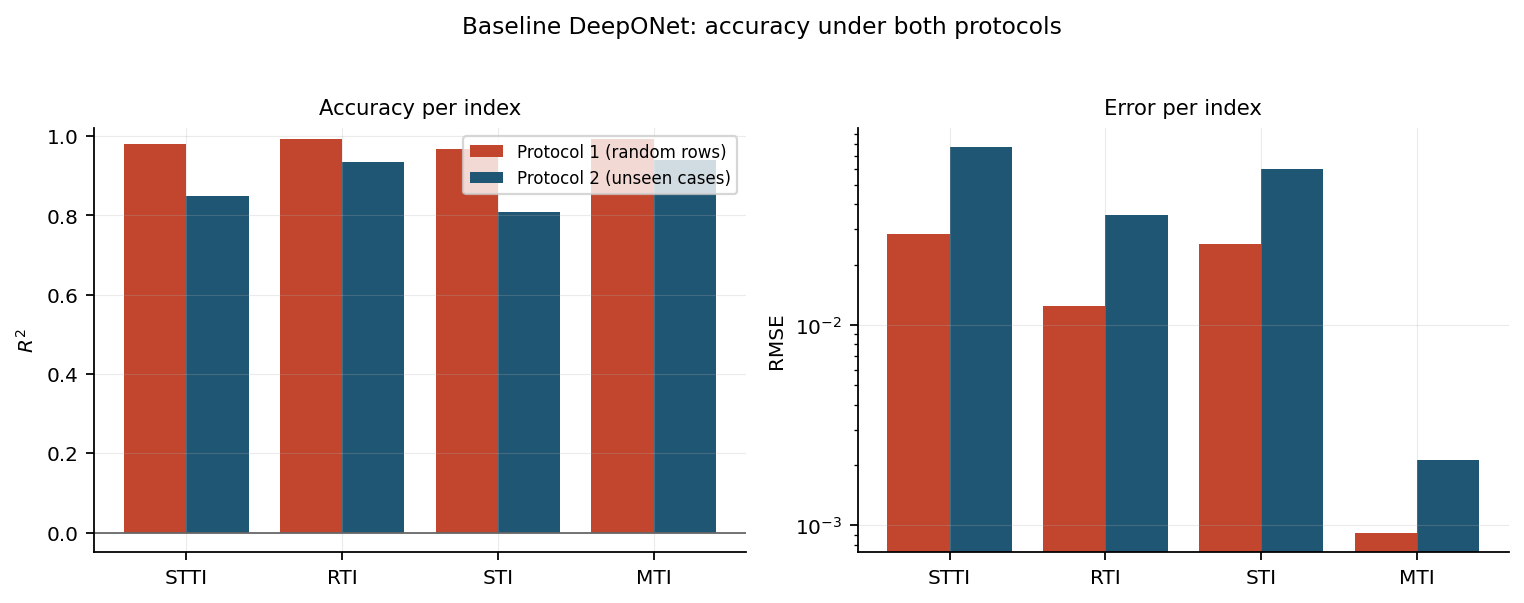

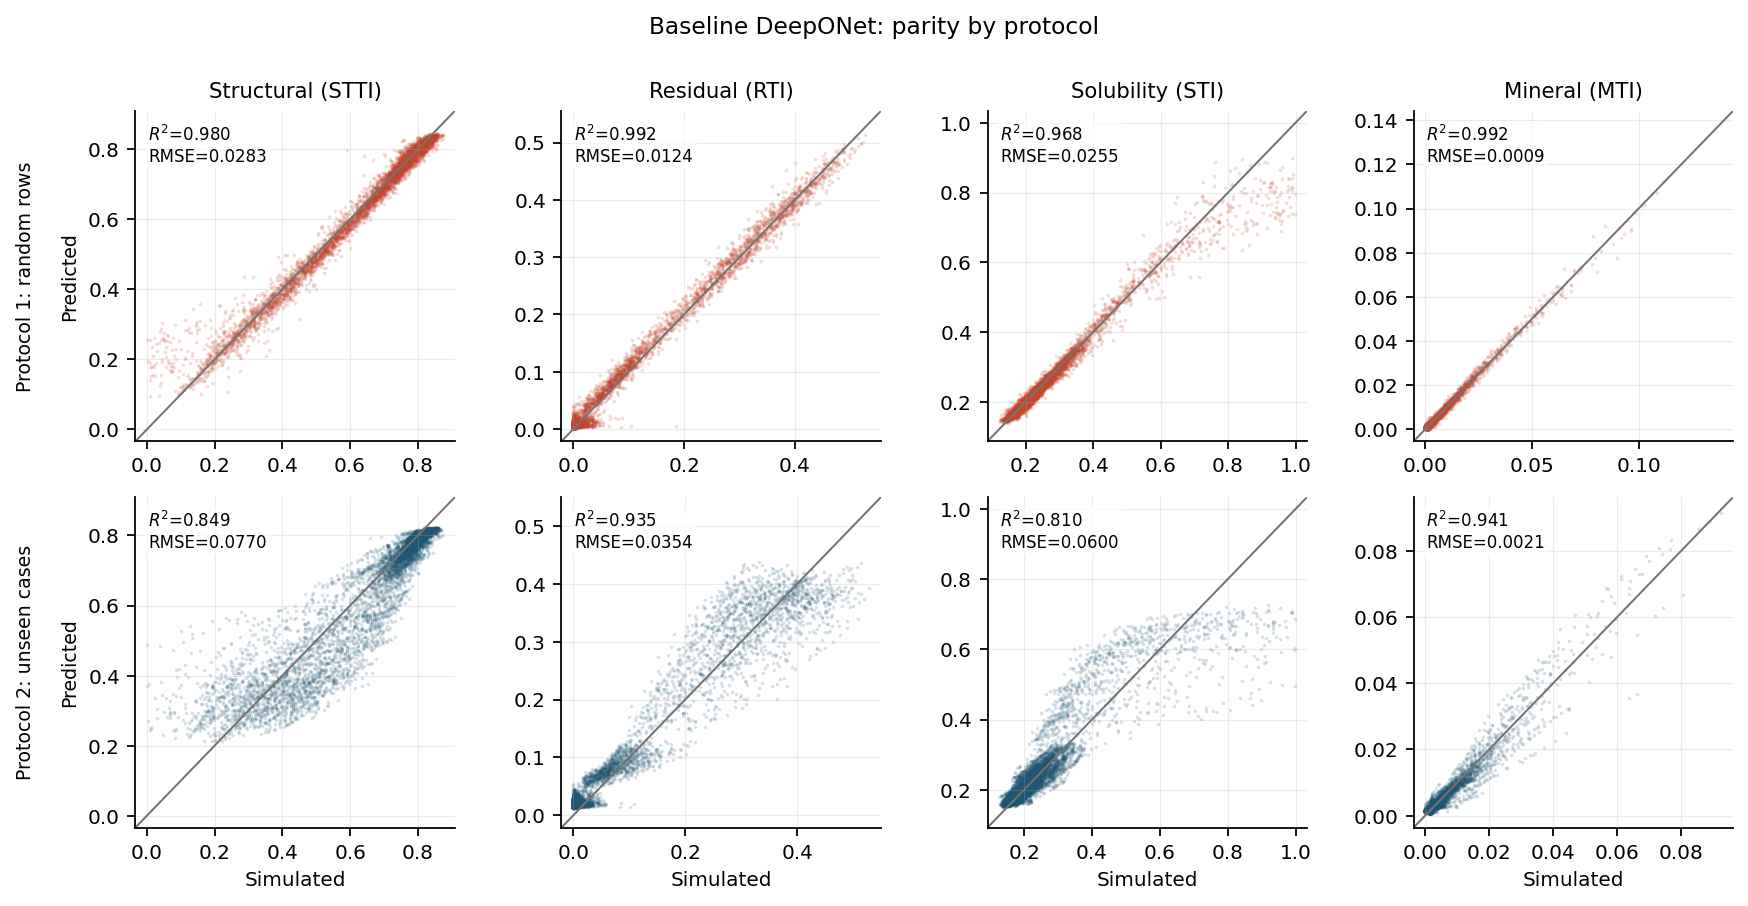

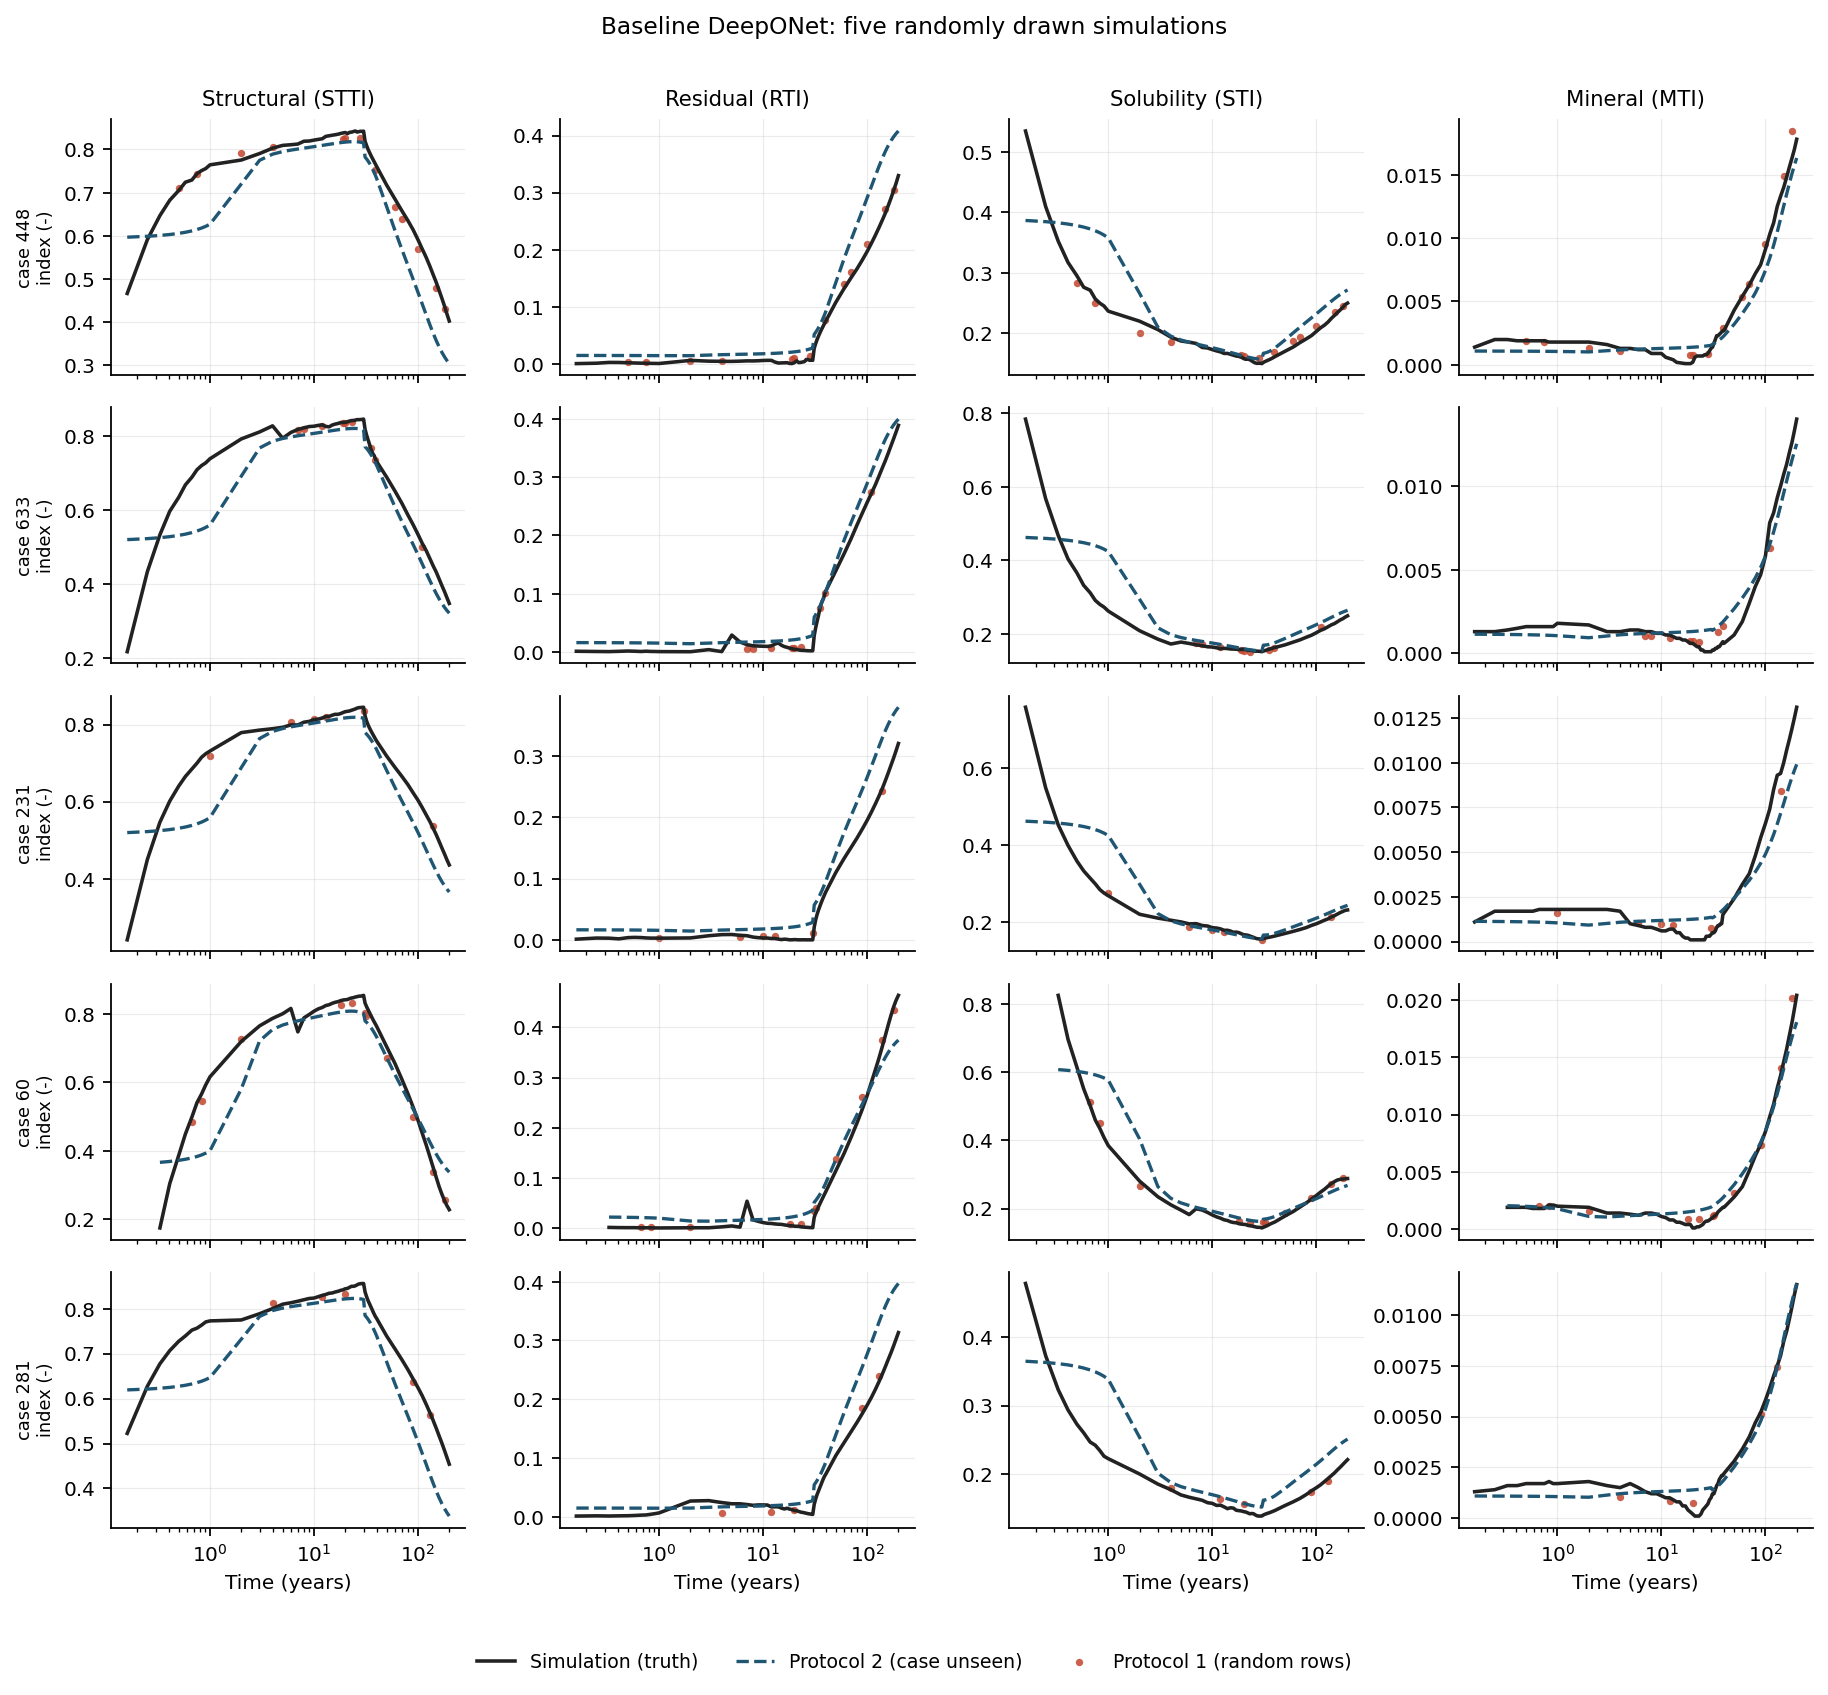

In [13]:
from IPython.display import Image, display

for f in [
    'baseline_protocol_bars',
    'baseline_parity',
    'baseline_trajectories'
]:
    display(Image(filename=f'figures_protocols/{f}.png'))

### Performance plot

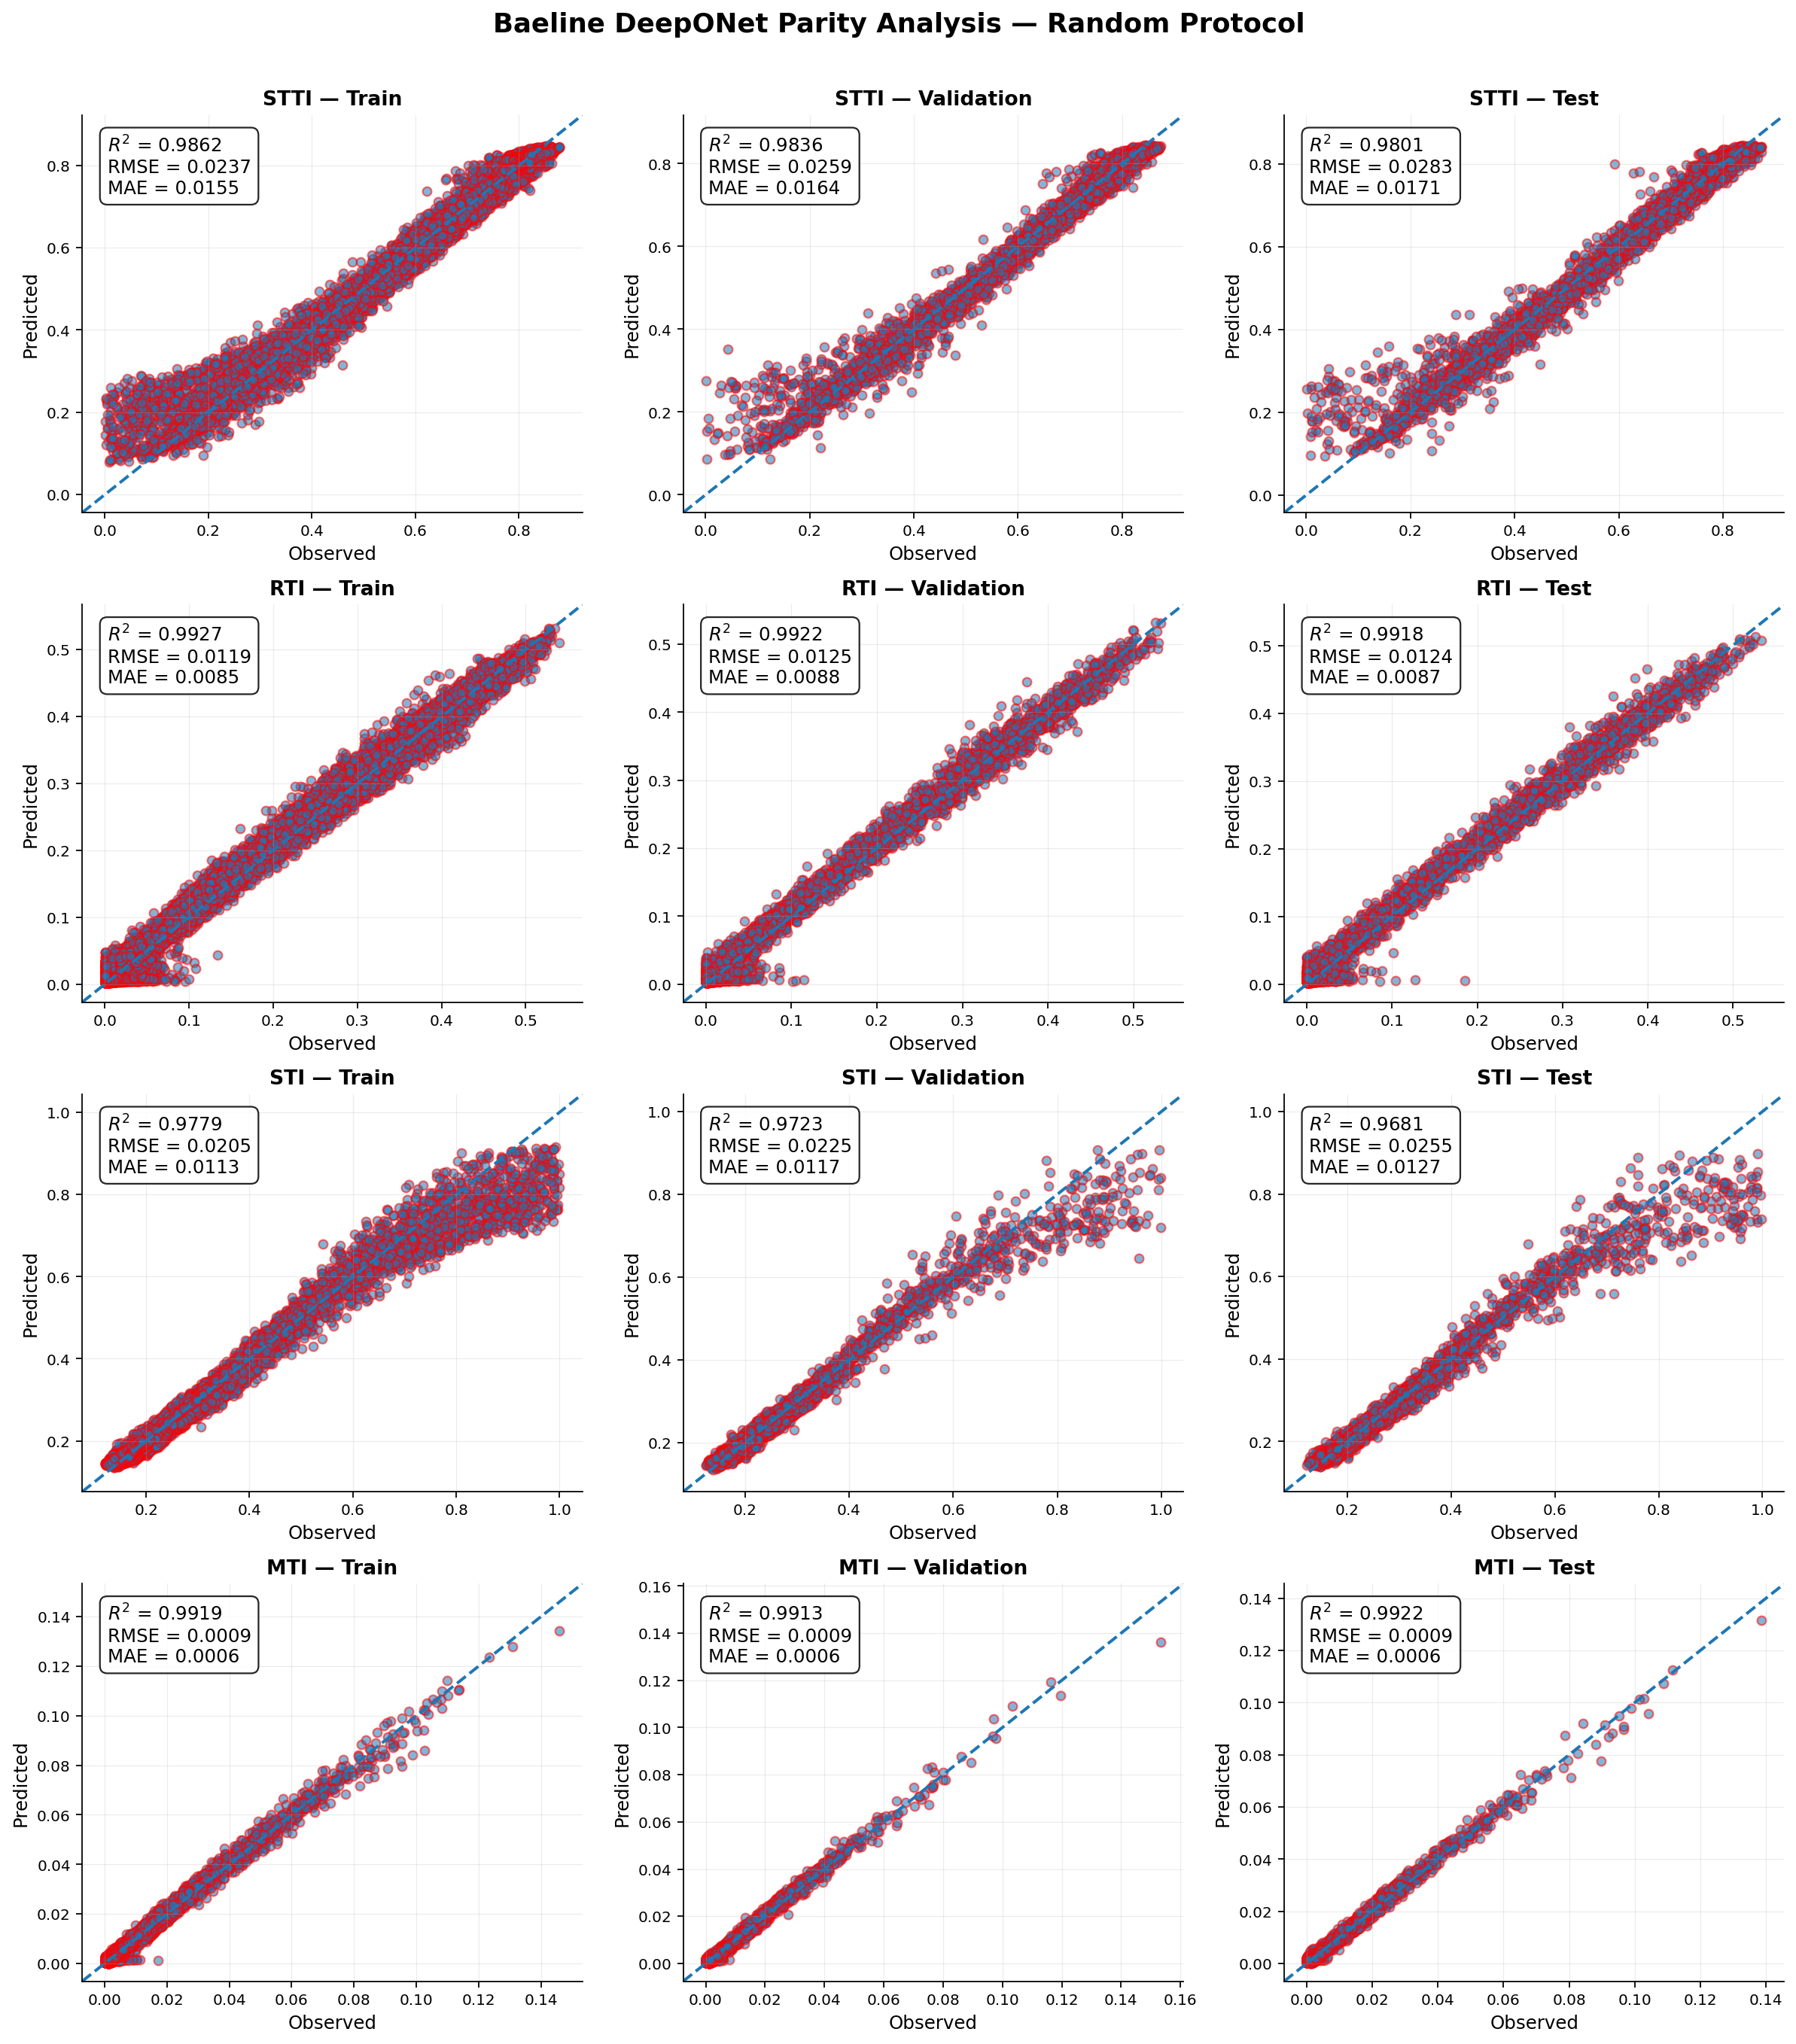

Saved: figures_protocols/baseline_parity_train_val_test_random.png


In [14]:
# ---- Baseline DeepONet: Train / Validation / Test parity plot ---------------
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('figures_protocols', exist_ok=True)

# ---------------------------------------------------------------------------
# Select the protocol you want to visualize
# ---------------------------------------------------------------------------
protocol = 'random'
model = models[protocol]
d = splits[protocol]

# Predictions for train / validation / test
P_tr = CC.predict_mean(model, d['Xb_tr'], d['Xt_tr'])
P_va = CC.predict_mean(model, d['Xb_va'], d['Xt_va'])
P_te = CC.predict_mean(model, d['Xb_te'], d['Xt_te'])

Y_tr = d['y_tr']
Y_va = d['y_va']
Y_te = d['y_te']

# ---------------------------------------------------------------------------
# Metric function
# ---------------------------------------------------------------------------
def parity_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    r2 = 1.0 - np.sum((y_true - y_pred) ** 2) / (
        np.sum((y_true - np.mean(y_true)) ** 2) + 1e-12
    )

    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))

    return r2, rmse, mae


# ---------------------------------------------------------------------------
# Create 4 × 3 parity figure
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(
    len(TARGETS),
    3,
    figsize=(15, 17)
)

sets = [
    ('Train', Y_tr, P_tr),
    ('Validation', Y_va, P_va),
    ('Test', Y_te, P_te)
]

for i, target in enumerate(TARGETS):

    for j, (set_name, y_true, y_pred) in enumerate(sets):

        ax = axes[i, j]

        yt = y_true[:, i]
        yp = y_pred[:, i]

        r2, rmse, mae = parity_metrics(yt, yp)

        # Determine common axis limits
        lo = min(yt.min(), yp.min())
        hi = max(yt.max(), yp.max())

        pad = 0.05 * (hi - lo + 1e-12)
        lo -= pad
        hi += pad

        # Scatter
        ax.scatter(
            yt,
            yp,
            alpha=0.55,
            s=28,
            edgecolors='red'
        )

        # 1:1 parity line
        ax.plot(
            [lo, hi],
            [lo, hi],
            linestyle='--',
            linewidth=1.8
        )

        # Metrics box
        ax.text(
            0.05,
            0.95,
            f'$R^2$ = {r2:.4f}\n'
            f'RMSE = {rmse:.4f}\n'
            f'MAE = {mae:.4f}',
            transform=ax.transAxes,
            verticalalignment='top',
            fontsize=11,
            bbox=dict(
                boxstyle='round,pad=0.4',
                facecolor='white',
                alpha=0.85
            )
        )

        # Labels
        ax.set_xlabel('Observed', fontsize=11)
        ax.set_ylabel('Predicted', fontsize=11)

        ax.set_title(
            f'{target} — {set_name}',
            fontsize=12,
            fontweight='bold'
        )

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        ax.grid(
            True,
            alpha=0.25
        )

# Overall title
fig.suptitle(
    f'Baeline DeepONet Parity Analysis — {protocol.capitalize()} Protocol',
    fontsize=16,
    fontweight='bold',
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.985])

# Save
outfile = (
    f'figures_protocols/'
    f'baseline_parity_train_val_test_{protocol}.png'
)

plt.savefig(
    outfile,
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print(f'Saved: {outfile}')